In [3]:
import sys
import tensorflow as tf

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Environment ready!")

Python: c:\Users\shrut_cbgwuxv\AI-PROJECTS\handwritten-digit-recognizer\venv\Scripts\python.exe
TensorFlow: 2.21.0
Environment ready!


In [4]:
from tensorflow.keras.datasets import mnist

# Load the dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset information
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("All libraries imported successfully!")

All libraries imported successfully!


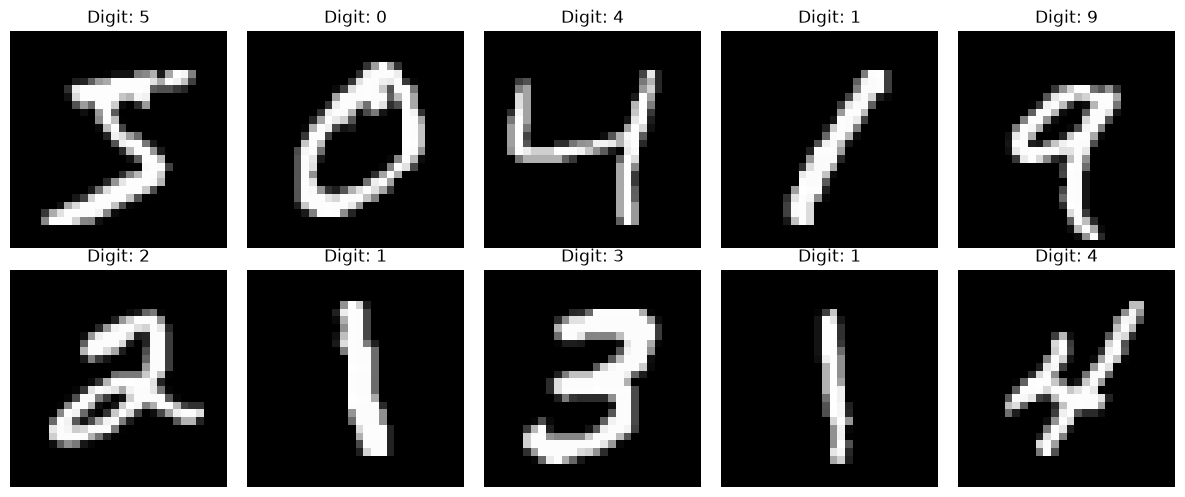

In [7]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Image shape: (28, 28)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


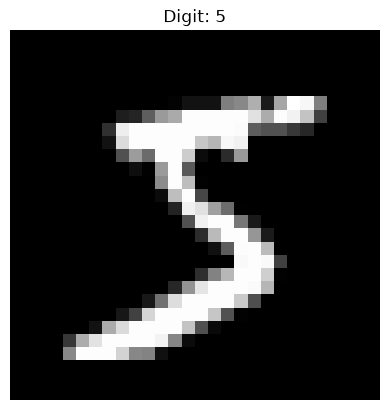

In [8]:
# Select the first training image
image = x_train[0]

# Display its information
print("Image shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())

# Display the image
plt.imshow(image, cmap="gray")
plt.title(f"Digit: {y_train[0]}")
plt.axis("off")
plt.show()

In [9]:
print(x_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

In [10]:
# Normalize training and testing images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum value:", x_train.min())
print("Maximum value:", x_train.max())

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Minimum value: 0.0
Maximum value: 1.0
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)


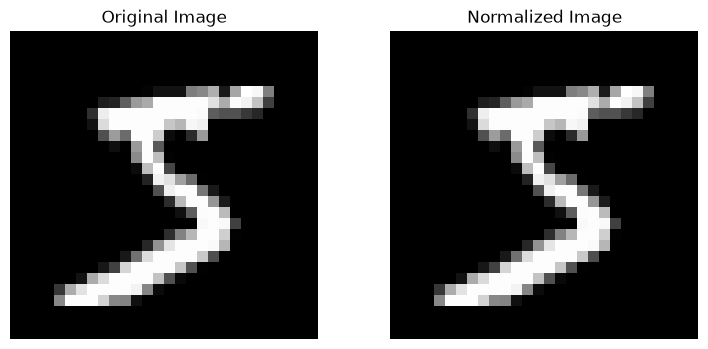

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(x_train[0], cmap="gray")
axes[1].set_title("Normalized Image")

for ax in axes:
    ax.axis("off")

plt.show()

In [12]:
# Add channel dimension to images

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [13]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

print("CNN layers imported successfully!")

CNN layers imported successfully!


In [14]:
model = Sequential([
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(28, 28, 1)
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dense(10, activation="softmax")
])

print("CNN model created successfully!")

c:\Users\shrut_cbgwuxv\AI-PROJECTS\handwritten-digit-recognizer\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN model created successfully!


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [17]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9467 - loss: 0.1864 - val_accuracy: 0.9807 - val_loss: 0.0735
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9813 - loss: 0.0618 - val_accuracy: 0.9857 - val_loss: 0.0545
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9875 - loss: 0.0412 - val_accuracy: 0.9827 - val_loss: 0.0577
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 26ms/step - accuracy: 0.9913 - loss: 0.0276 - val_accuracy: 0.9890 - val_loss: 0.0432
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9941 - loss: 0.0191 - val_accuracy: 0.9877 - val_loss: 0.0493


In [18]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9842 - loss: 0.0476
Test Accuracy: 98.42000007629395 %
Test Loss: 0.047566238790750504


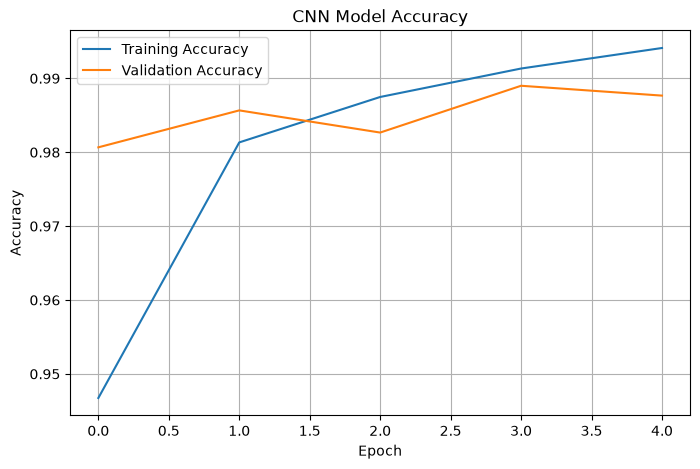

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

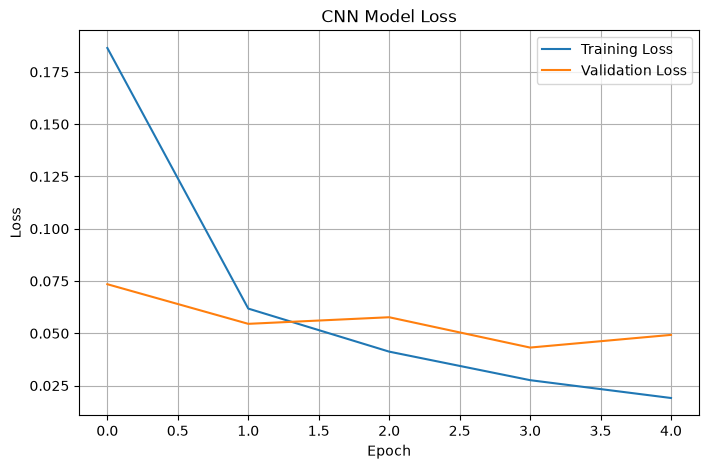

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

Image shape: (28, 28, 1)
Actual digit: 0


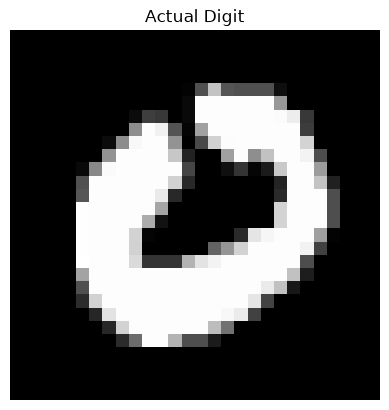

In [21]:
# Select one image from the test dataset

index = 25

image = x_test[index]

print("Image shape:", image.shape)
print("Actual digit:", y_test[index])

plt.imshow(image.squeeze(), cmap="gray")
plt.title("Actual Digit")
plt.axis("off")
plt.show()

In [22]:
# Make a prediction

prediction = model.predict(x_test[index:index+1])

predicted_digit = np.argmax(prediction)

print("Predicted Digit:", predicted_digit)
print("Actual Digit:", y_test[index])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
Predicted Digit: 0
Actual Digit: 0


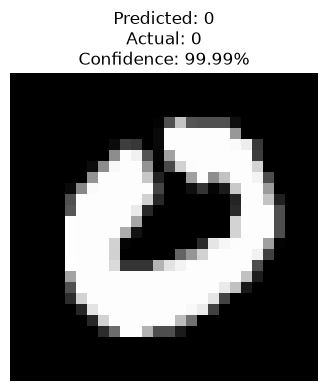

In [23]:
confidence = np.max(prediction) * 100

plt.figure(figsize=(4, 4))
plt.imshow(x_test[index].squeeze(), cmap="gray")
plt.title(
    f"Predicted: {predicted_digit}\n"
    f"Actual: {y_test[index]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

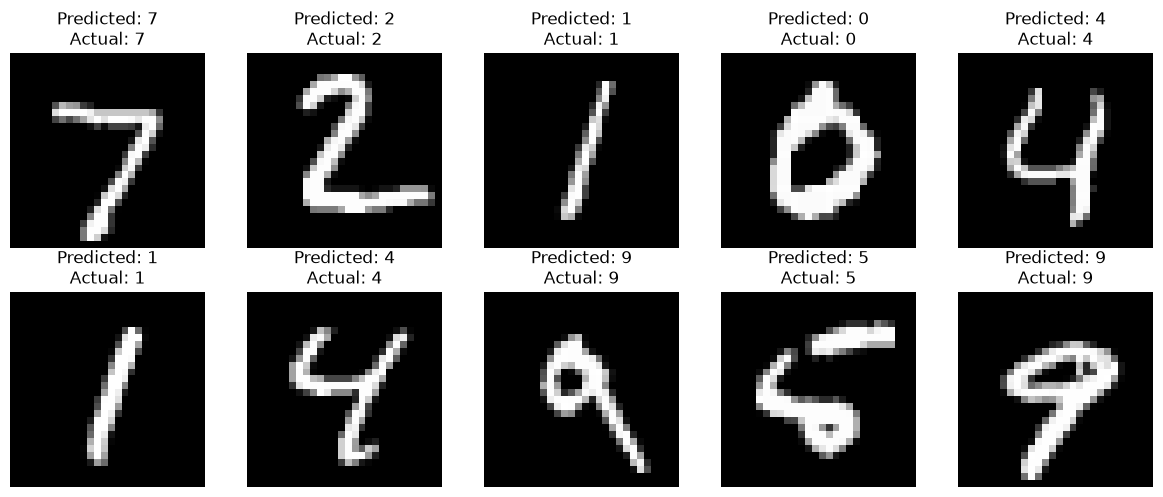

In [24]:
plt.figure(figsize=(12, 5))

for i in range(10):
    prediction = model.predict(
        x_test[i:i+1],
        verbose=0
    )

    predicted_digit = np.argmax(prediction)

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")

    plt.title(
        f"Predicted: {predicted_digit}\n"
        f"Actual: {y_test[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
model.save("digit_recognizer.keras")

print("Model saved successfully!")

Model saved successfully!


In [26]:
from tensorflow.keras.models import load_model

loaded_model = load_model("digit_recognizer.keras")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [1]:
# Test the trained CNN on an original MNIST image

index = 25

test_image = x_test[index:index+1]

prediction = model.predict(test_image, verbose=0)

predicted_digit = np.argmax(prediction)

confidence = np.max(prediction) * 100

plt.imshow(x_test[index].squeeze(), cmap="gray")
plt.title(
    f"Predicted: {predicted_digit} | "
    f"Actual: {y_test[index]}"
)
plt.axis("off")
plt.show()

print("Prediction:", predicted_digit)
print("Confidence:", round(confidence, 2), "%")

NameError: name 'x_test' is not defined

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Load our previously trained CNN
model = load_model("digit_recognizer.keras")

print("MNIST dataset loaded!")
print("Saved CNN model loaded!")
print("Test images:", x_test.shape)

MNIST dataset loaded!
Saved CNN model loaded!
Test images: (10000, 28, 28, 1)


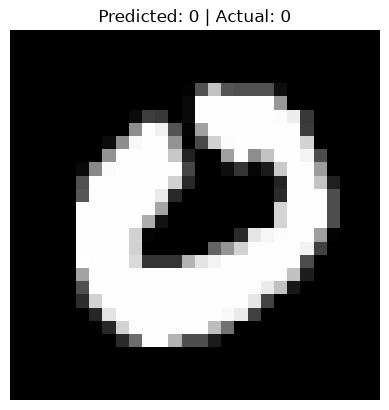

Prediction: 0
Actual: 0
Confidence: 99.99 %


In [2]:
index = 25

prediction = model.predict(x_test[index:index+1], verbose=0)

predicted_digit = np.argmax(prediction)
confidence = np.max(prediction) * 100

plt.imshow(x_test[index].squeeze(), cmap="gray")
plt.title(f"Predicted: {predicted_digit} | Actual: {y_test[index]}")
plt.axis("off")
plt.show()

print("Prediction:", predicted_digit)
print("Actual:", y_test[index])
print("Confidence:", round(confidence, 2), "%")

In [3]:
for index in [10, 25, 50, 100, 200]:

    prediction = model.predict(
        x_test[index:index+1],
        verbose=0
    )

    predicted_digit = np.argmax(prediction)
    actual_digit = y_test[index]

    print(
        f"Image {index} | "
        f"Predicted: {predicted_digit} | "
        f"Actual: {actual_digit}"
    )

Image 10 | Predicted: 0 | Actual: 0
Image 25 | Predicted: 0 | Actual: 0
Image 50 | Predicted: 6 | Actual: 6
Image 100 | Predicted: 6 | Actual: 6
Image 200 | Predicted: 3 | Actual: 3
